In [ ]:
import os
import pickle
import sys
import time

import numpy as np
import shutil
import matplotlib.pyplot as plt
import librosa
import sklearn
from pathlib import Path
from sklearn.datasets import make_classification
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC, SVC
from joblib import Parallel, delayed

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "\npandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.14.5
NumPy: 2.5.4 
pandas: 3.0.6
scikit-learn: 1.9.1


In [ ]:
from testing_files.GTZANBaselineClassifier import GTZANBaselineClassifier



def do_baseline_Class(feats):
    pipeline = GTZANBaselineClassifier(feature_subset=feats)
    pipeline.load_and_prepare_data().split_data()

    best_k, fig_val, ax_val = pipeline.find_best_k(displayPlot=True) # Renders inline in notebook cell
    pipeline.train_models()

    fig_acc, ax_acc = pipeline.plot_test_accuracies(displayPlot=True) # Renders inline
    pipeline.plot_confusion_matrices(displayPlot=True)                # Renders inline

    pipeline.compute_and_store_metrics()
    pipeline.print_metrics_summary()
    pipeline.print_per_class_metrics('KNN + Linear SVM (Ensemble)')
    return pipeline



# mfcc_pipeline = do_baseline_Class('mfcc')
# spec_pipeline = do_baseline_Class('spectral')
# full_pipeline = do_baseline_Class('full')

In [ ]:
from GTZANClassifier import GTZANClassifier

def train_all_n_save_models(
        dirpath='./GTZAN/Data_filtered/30s_split/', rand_state=42):
    subsets = ['full', 'spectral', 'mfcc']
    saved_model_paths = {}

    for subset in subsets:
        print(f"\n--- Processing Feature Subset: {subset.upper()} ---")
        
        # Instantiate for each subset
        clf = GTZANClassifier(
            dirpath=dirpath,
            feature_subset=subset,
            random_state=rand_state
        )
        
        # Run pipeline steps
        clf.load_and_prepare_data()
        clf.find_best_k()
        clf.train_baseline_models()
        clf.train_models()
        clf.compute_and_store_metrics()
        
        path = f'./trained_models'
        clf.save_models(path)
        saved_model_paths[subset] = path
    return saved_model_paths


# for t in ['30', '3']:
#     for rng in [42, 351, 605]:
#         train_all_n_save_models(
#             dirpath=f'./GTZAN/Data_filtered/{t}s_split/',
#             rand_state=rng)
#         print("="*50)


--- Processing Feature Subset: FULL ---
Loading TRAIN split from: train_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\train_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading TEST split from: test_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\test_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading VAL split from: valid_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\valid_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Train size: 463 | Val size: 203 | Test size: 300
winning k chosen for KNN: 12
Training/Evaluating KNN...
-> Done in 0.0021s | Test Error: 0.5967

Training/Evaluating Linear SVM...
-> Done in 0.0153s | Test Error: 0.5267

Training/Evaluating KNN + Linear SVM (Ensemble)...
-> Done in 0.0174s | Test Error: 0.5633

Running Grid Search for SVM...
Running Grid Search for Random Forest...
Running Grid Searc

In [6]:
import pandas as pd
import GTZANDataProcessor as gdp

In [11]:
splits_30s = gdp.summarize_split_distributions('./GTZAN/Data_filtered/30s_split/')
splits_3s = gdp.summarize_split_distributions('./GTZAN/Data_filtered/3s_split/')


SPLIT SUMMARY: TEST (Total Samples: 300)
           Count  Percentage
label                       
blues         31       10.33
classical     31       10.33
country       30       10.00
disco         30       10.00
hiphop        33       11.00
jazz          27        9.00
metal         27        9.00
pop           30       10.00
reggae        26        8.67
rock          35       11.67

SPLIT SUMMARY: TRAIN (Total Samples: 463)
           Count  Percentage
label                       
blues         46        9.94
classical     51       11.02
country       45        9.72
disco         44        9.50
hiphop        56       12.10
jazz          49       10.58
metal         44        9.50
pop           41        8.86
reggae        43        9.29
rock          44        9.50

SPLIT SUMMARY: VALID (Total Samples: 203)
           Count  Percentage
label                       
blues         23       11.33
classical     20        9.85
country       26       12.81
disco         25       12.32
hi

In [8]:
def get_split_summary(split_dict, metric="count"):
  """Combines train, test, and validation split dataframes into a single summary table.

  Args:
      split_dict (dict): The dictionary containing split dataframes.
      metric (str): The metric to display, either 'count' or 'percentage'.

  Returns:
      pd.DataFrame: DataFrame with genre labels as index and
                    ['train', 'test', 'valid'] as columns.
  """
  # Map user input to the correct DataFrame column name
  col_name = "Count" if metric.lower() == "count" else "Percentage"

  # Extract the requested column from each split dataframe
  summary_data = {}
  for split_name in ["train", "test", "valid"]:
    if split_name in split_dict:
      summary_data[split_name] = split_dict[split_name]["dataframe"][col_name]

  # Build the consolidated DataFrame and enforce column order
  df_summary = pd.DataFrame(summary_data)[["train", "test", "valid"]]

  # Print to the console
  print(f"\n--- Dataset Split Summary: {metric.upper()} ---")
  print(df_summary.to_string())
  print("-" * 45)

  return df_summary


In [17]:
foo = get_split_summary(splits_30s, metric="count")


--- Dataset Split Summary: COUNT ---
           train  test  valid
label                        
blues         46    31     23
classical     51    31     20
country       45    30     26
disco         44    30     25
hiphop        56    33     18
jazz          49    27     17
metal         44    27     20
pop           41    30     13
reggae        43    26     17
rock          44    35     24
---------------------------------------------


In [25]:
print(foo.sum() )
print(foo.sum() / foo.sum().sum() )

train    463
test     300
valid    203
dtype: int64
train    0.479296
test     0.310559
valid    0.210145
dtype: float64


In [1]:
import GTZANDataProcessor as gdp

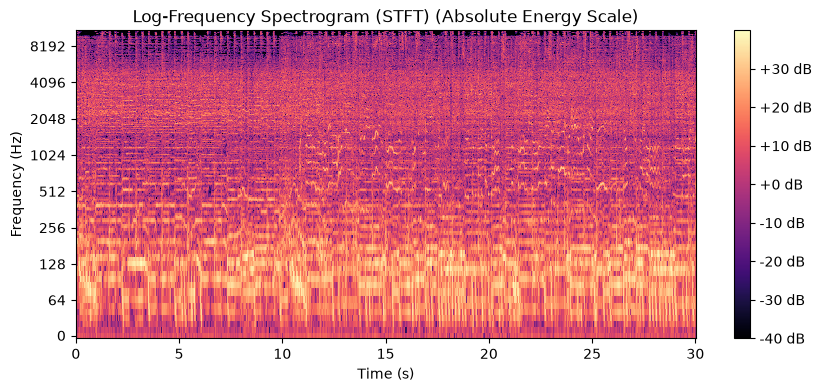

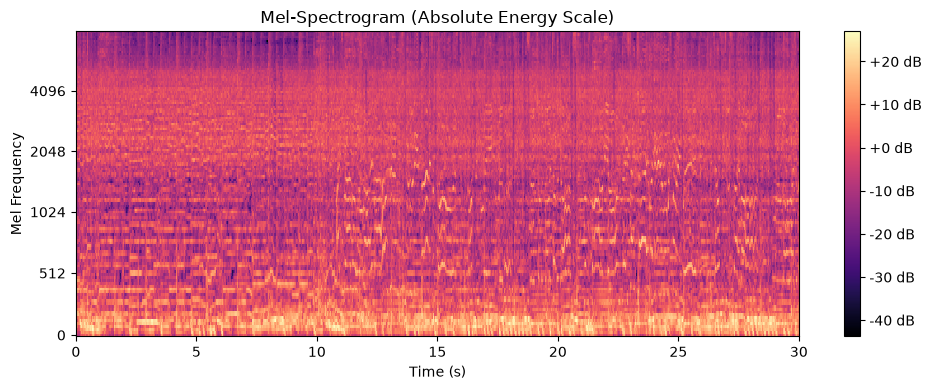

In [2]:

gdp.plot_spectrogram('./GTZAN/Data/genres_original/metal/metal.00000.wav',oneFig=False)

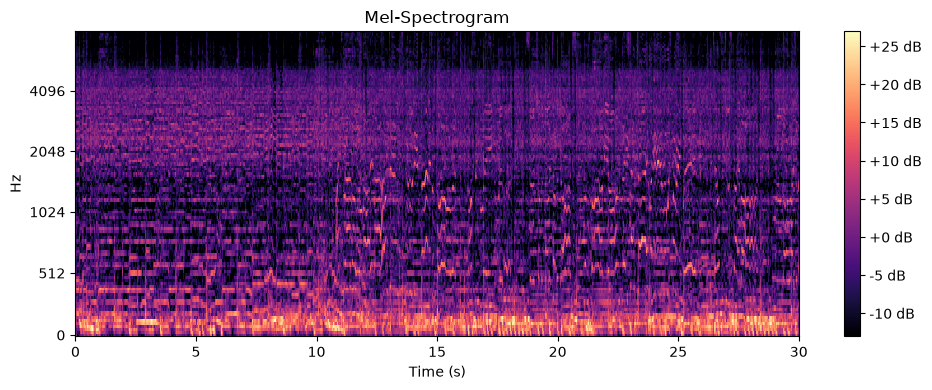

In [8]:
gdp.plot_reference_style_spectrogram('./GTZAN/Data/genres_original/metal/metal.00000.wav',top_db=40.0)

In [4]:
gdp.get_split_summary()

TypeError: get_split_summary() missing 1 required positional argument: 'split_dict'

In [16]:
df = pd.read_csv("./GTZAN/Data_filtered/30s_split/valid_filtered_30s_features.csv")
print(df[['filename', 'chroma_stft_mean', 'rms_mean','spectral_centroid_mean','tempo','label']].head())

          filename  chroma_stft_mean  rms_mean  spectral_centroid_mean  \
0  blues.00000.wav          0.349951  0.130192             1784.416546   
1  blues.00001.wav          0.340945  0.095892             1529.871314   
2  blues.00002.wav          0.363562  0.175494             1552.637786   
3  blues.00003.wav          0.404848  0.141139             1070.110059   
4  blues.00004.wav          0.308598  0.091540             1835.507008   

        tempo  label  
0  123.046875  blues  
1   67.999589  blues  
2  161.499023  blues  
3   63.024009  blues  
4  135.999178  blues  


In [ ]:
df.columns

Index(['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean',
       'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var',
  